
# Ensemble Learning in Machine Learning

## Objective
In this notebook, we will implement and compare different ensemble learning techniques using Python and Scikit-learn.

We will explore:
- Voting Classifier
- Bagging Classifier
- Random Forest
- Boosting Algorithms

We will compare these models with a single Decision Tree to understand when and why ensemble methods can improve performance.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score

In [2]:
X,y = make_classification(
    n_samples = 2500,
    n_features = 10,
    n_informative = 5,
    n_redundant = 2,
    n_classes = 2,
    random_state = 2
)

print("Features Shape: ",X.shape)
print("Target Classes: ",y.shape)

Features Shape:  (2500, 10)
Target Classes:  (2500,)


In [3]:
# Display the first 5 samples
print("First 5 samples:\n", X[:5])

# Display the first 5 target labels
print("\nFirst 5 target labels:", y[:5])

# Check the number of samples in each class
print("\nClass distribution:")
print(pd.Series(y).value_counts())

First 5 samples:
 [[ 9.90681825e-01 -2.56435764e+00 -9.81152791e-01  2.36233851e-01
   1.17016764e+00  2.84617083e-01 -1.49832241e+00  1.33260703e+00
  -5.42415485e-01 -9.57168698e-01]
 [-9.68622384e-01 -6.76166218e-01 -6.46537657e-01  1.88848926e+00
   1.00730180e+00  1.62249685e+00  1.23680808e+00 -1.59909756e+00
   2.79932405e+00  2.24466224e+00]
 [-2.24169330e-01 -2.19651644e+00  1.24961834e-02  6.48750941e-01
   3.81546417e+00  2.86678888e-03  6.23938889e-01  1.10343604e+00
   1.48984388e+00  2.56312805e-01]
 [ 4.09416910e-01 -1.11670411e+00  4.37826458e-01  1.55403953e+00
   9.14409861e-01 -1.64442488e-03  2.69480642e-01  2.53490063e+00
  -4.25512290e-01 -6.86030989e-01]
 [-3.11466959e-01 -3.01395047e+00 -1.66251262e+00  9.63821545e-01
   1.29448181e+00  4.53216924e-03 -1.27437187e+00 -1.54811574e+00
  -5.09342894e-01 -1.14272895e+00]]

First 5 target labels: [0 0 0 0 0]

Class distribution:
0    1254
1    1246
Name: count, dtype: int64


In [4]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state = 42,
    stratify = y #preserves the class proportion in both test and train
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (2000, 10)
X_test: (500, 10)
y_train: (2000,)
y_test: (500,)


In [5]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state = 42)

dt_model.fit(X_train,y_train)

y_pred = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test,y_pred)

print("Decision Tree Accuracy : ", dt_accuracy)

Decision Tree Accuracy :  0.928


In [6]:
# Calculate training accuracy
train_pred = dt_model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)

print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", dt_accuracy)

Train Accuracy: 1.0
Test Accuracy: 0.928



## 3. Voting Classifier

A Voting Classifier combines predictions from multiple machine learning models to make a final prediction.

- **Hard Voting:** Each model votes for a class, and the majority class wins.
- **Soft Voting:** Each model provides class probabilities, and the class with the highest average probability is selected.

The goal is to determine whether combining different models improves performance compared with a single Decision Tree.


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

## Hard voting

In [8]:
lr = make_pipeline(StandardScaler(),LogisticRegression(random_state = 42))
knn = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors = 5))
dt = DecisionTreeClassifier(random_state =42)

voting_model = VotingClassifier(
    estimators=[
        ('lr',lr),
        ('knn',knn),
        ('dt',dt)
    ],
    voting = 'hard'
)

voting_model.fit(X_train,y_train)

voting_pred = voting_model.predict(X_test)
voting_accuracy = accuracy_score(y_test,voting_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("hard Voting Classifier Accuracy:", voting_accuracy)

Decision Tree Accuracy: 0.928
hard Voting Classifier Accuracy: 0.956


## Soft Voting

In [9]:
lr = make_pipeline(StandardScaler(),LogisticRegression(random_state = 42))
knn = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors = 5))
dt = DecisionTreeClassifier(random_state =42)

voting_model = VotingClassifier(
    estimators=[
        ('lr',lr),
        ('knn',knn),
        ('dt',dt)
    ],
    voting = 'soft'
)

voting_model.fit(X_train,y_train)

voting_pred = voting_model.predict(X_test)
voting_accuracy = accuracy_score(y_test,voting_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("soft Voting Classifier Accuracy:", voting_accuracy)

Decision Tree Accuracy: 0.928
soft Voting Classifier Accuracy: 0.95



## 4. Bagging (Bootstrap Aggregating)

Bagging trains multiple models on different bootstrap samples of the training data. A bootstrap sample is created by randomly sampling observations with replacement.

For classification, the models combine their predictions using majority voting.

**Goal:** Compare a single Decision Tree against an ensemble of Decision Trees and observe whether combining them reduces overfitting.


In [10]:
from sklearn.ensemble import BaggingClassifier

bagging_model = BaggingClassifier(
    estimator = DecisionTreeClassifier(random_state = 42),
    n_estimators=50,
    random_state=42
)

bagging_model.fit(X_train,y_train)

bagging_pred = bagging_model.predict(X_test)

bagging_accuracy = accuracy_score(y_test,bagging_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Bagging Classifier Accuracy:", bagging_accuracy)

Decision Tree Accuracy: 0.928
Bagging Classifier Accuracy: 0.954


## lets try bagging for diferent number of decision trees

In [11]:
for n in [1,10,50,100]:
    model = BaggingClassifier(
        estimator = DecisionTreeClassifier(random_state=42),
        n_estimators = n,
        random_state =42
    )

    model.fit(X_train,y_train)
    pred = model.predict(X_test)

    print(f"Trees: {n:3} | Test Accuracy: {accuracy_score(y_test, pred):.3f}")
    

Trees:   1 | Test Accuracy: 0.920
Trees:  10 | Test Accuracy: 0.954
Trees:  50 | Test Accuracy: 0.954
Trees: 100 | Test Accuracy: 0.962



## 5. Random Forest

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees.

Like Bagging, it trains trees on bootstrap samples. However, at each split, it also considers a random subset of features rather than all available features.

This additional randomness helps reduce correlation between trees and can improve generalization.

We will compare Random Forest with our single Decision Tree and Bagging models.


In [12]:
from sklearn.ensemble import RandomForestClassifier


rf_model = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42
)

rf_model.fit(X_train,y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test,rf_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Bagging Accuracy:", bagging_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

Decision Tree Accuracy: 0.928
Bagging Accuracy: 0.954
Random Forest Accuracy: 0.966


### Experimenting with the hyperparameters in RandomForest

In [13]:
# Experiment with different Random Forest configurations
configs = [
    {"n_estimators": 10, "max_depth": None, "max_features": "sqrt"},
    {"n_estimators": 100, "max_depth": None, "max_features": "sqrt"},
    {"n_estimators": 100, "max_depth": 5, "max_features": "sqrt"},
    {"n_estimators": 100, "max_depth": None, "max_features": None}
]

for config in configs:
    model = RandomForestClassifier(**config, random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        f"Trees: {config['n_estimators']:3}, "
        f"Depth: {str(config['max_depth']):4}, "
        f"Features: {str(config['max_features']):5} | "
        f"Accuracy: {accuracy_score(y_test, pred):.3f}"
    )

Trees:  10, Depth: None, Features: sqrt  | Accuracy: 0.950
Trees: 100, Depth: None, Features: sqrt  | Accuracy: 0.966
Trees: 100, Depth: 5   , Features: sqrt  | Accuracy: 0.954
Trees: 100, Depth: None, Features: None  | Accuracy: 0.964


### Feature imprtances given by our Random Forest Model

In [14]:
importance = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": [f"Feature {i}" for i in range(X.shape[1])],
    "Importance": importance
})


feature_importance_df = feature_importance_df.sort_values(
    by = "Importance",
    ascending = False
)

print(feature_importance_df)

     Feature  Importance
4  Feature 4    0.265884
8  Feature 8    0.170746
1  Feature 1    0.156729
6  Feature 6    0.118681
3  Feature 3    0.099878
2  Feature 2    0.083920
9  Feature 9    0.065369
0  Feature 0    0.013410
5  Feature 5    0.012964
7  Feature 7    0.012419


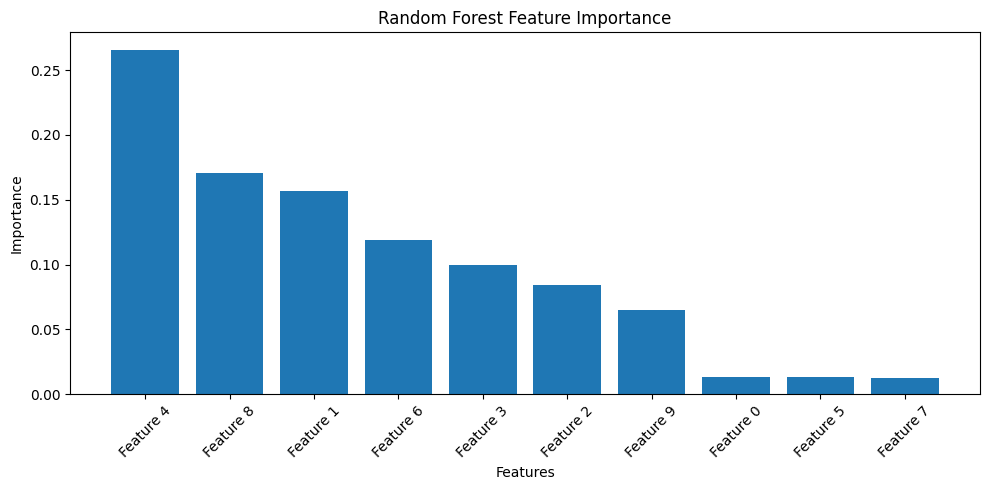

In [15]:
# Plot feature importance
plt.figure(figsize=(10, 5))

plt.bar(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)

plt.xticks(rotation=45)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


## 6. Boosting

Boosting is an ensemble learning technique in which models are trained sequentially to improve predictive performance.

- **AdaBoost:** Increases the emphasis on previously misclassified training samples so subsequent learners focus more on difficult examples.
- **Gradient Boosting:** Builds new models to reduce the errors of the current ensemble by optimizing a loss function.

Unlike Bagging, which primarily reduces variance by combining independently trained models, boosting often improves performance by reducing bias and correcting errors over successive stages.


In [16]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(
    n_estimators = 50,
    random_state = 42
)

ada_model.fit(X_train,y_train)

ada_pred = ada_model.predict(X_test)

ada_accuracy = accuracy_score(y_test,ada_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Random Forest Accuracy:", rf_accuracy)
print("AdaBoost Accuracy:", ada_accuracy)

Decision Tree Accuracy: 0.928
Random Forest Accuracy: 0.966
AdaBoost Accuracy: 0.914


In [17]:
for n in [10,50,100,200]:
    model = AdaBoostClassifier(
        n_estimators = n,
        random_state = 42
    )
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_pred,y_test)
    print(f"Estimators: {n:3} | Test Accuracy: {acc:.3f}")

Estimators:  10 | Test Accuracy: 0.900
Estimators:  50 | Test Accuracy: 0.914
Estimators: 100 | Test Accuracy: 0.924
Estimators: 200 | Test Accuracy: 0.928


## Gradient Boosting

### 1. What is Gradient Boosting?

Gradient Boosting is an ensemble learning technique that combines multiple weak learners, typically shallow Decision Trees, to build a strong predictive model.

The trees are trained **sequentially**, with each new tree attempting to reduce the errors made by the existing ensemble by minimizing a loss function.

### 2. How Does It Work?

1. **Initialize:** Start with an initial prediction.
2. **Calculate errors:** Compute the negative gradients of the loss function, called *pseudo-residuals*.
3. **Train a tree:** Fit a new Decision Tree to learn patterns in these pseudo-residuals.
4. **Update predictions:** Add the new tree's contribution to the existing model.
5. **Repeat:** Continue until the specified number of trees is reached.

### 3. Mathematical Intuition

The model is built additively:

$$
F_m(x)=F_{m-1}(x)+\eta h_m(x)
$$

Where:
- \(F_{m-1}(x)\): Current model prediction.
- \(h_m(x)\): New tree's contribution.
- \(\eta\): Learning rate, controlling the contribution of each tree.

For squared-error regression, the negative gradients are equivalent to ordinary residuals:

$$
r_i=y_i-\hat{y}_i
$$

For classification, the algorithm instead uses gradients derived from a classification loss, such as log loss.

### 4. Gradient Boosting vs. AdaBoost

| AdaBoost | Gradient Boosting |
|---|---|
| Updates sample weights to focus on difficult examples. | Fits new learners to negative gradients of a loss function. |
| Commonly explained through weighted classification errors. | Uses a general loss-minimization framework. |
| Combines weak learners using weighted predictions. | Adds learners sequentially to the existing model. |

Both methods build ensembles sequentially, but their mechanisms for improving predictions differ.

### 5. Important Hyperparameters

- **`n_estimators`**: Number of boosting stages.
- **`learning_rate`**: Controls each tree's contribution.
- **`max_depth`**: Controls the complexity of each tree.

**Key takeaway:** Gradient Boosting improves a model iteratively by adding trees that help reduce its loss. Too many trees or overly complex trees can lead to overfitting.



### Gradient Boosting

Gradient Boosting builds an ensemble sequentially, with each new model learning to reduce the errors of the current ensemble.

Unlike AdaBoost, which adjusts the weights of misclassified samples, Gradient Boosting fits new learners to the residual errors (or, more generally, the negative gradients of a loss function).

We will compare its performance with AdaBoost and Random Forest.


In [18]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators = 100,
    max_depth = 3,
    random_state = 42 
)

gb_model.fit(X_train,y_train)
y_pred = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test,y_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Random Forest Accuracy:", rf_accuracy)
print("AdaBoost Accuracy:", ada_accuracy)
print("Gradient Boosting Accuracy:", gb_accuracy)

Decision Tree Accuracy: 0.928
Random Forest Accuracy: 0.966
AdaBoost Accuracy: 0.914
Gradient Boosting Accuracy: 0.968


In [19]:
# Experiment with different numbers of boosting stages
for n in [10, 50, 100, 200]:
    model = GradientBoostingClassifier(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(f"Estimators: {n} | Accuracy: {accuracy_score(y_test, pred):.3f}")

Estimators: 10 | Accuracy: 0.930
Estimators: 50 | Accuracy: 0.952
Estimators: 100 | Accuracy: 0.968
Estimators: 200 | Accuracy: 0.968



## 7. Final Model Comparison

We have trained several individual and ensemble classifiers.

In this section, we will compare their test accuracies to identify which models performed best on our dataset.

Remember that accuracy depends on the dataset, train-test split, and model parameters. An ensemble does not always outperform a single model.


In [20]:
# Store model names and their test accuracies
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Hard Voting",
        "Soft Voting",
        "Bagging",
        "Random Forest",
        "AdaBoost",
        "Gradient Boosting"
    ],
    "Test Accuracy": [
        dt_accuracy,
        0.956,  # Hard Voting accuracy from our experiment
        0.950,  # Soft Voting accuracy from our experiment
        bagging_accuracy,
        rf_accuracy,
        ada_accuracy,
        gb_accuracy
    ]
})

# Sort models by accuracy
results = results.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

results

,Model,Test Accuracy
0,Gradient Boosting,0.968
1,Random Forest,0.966
2,Hard Voting,0.956
3,Bagging,0.954
4,Soft Voting,0.950
5,Decision Tree,0.928
6,AdaBoost,0.914


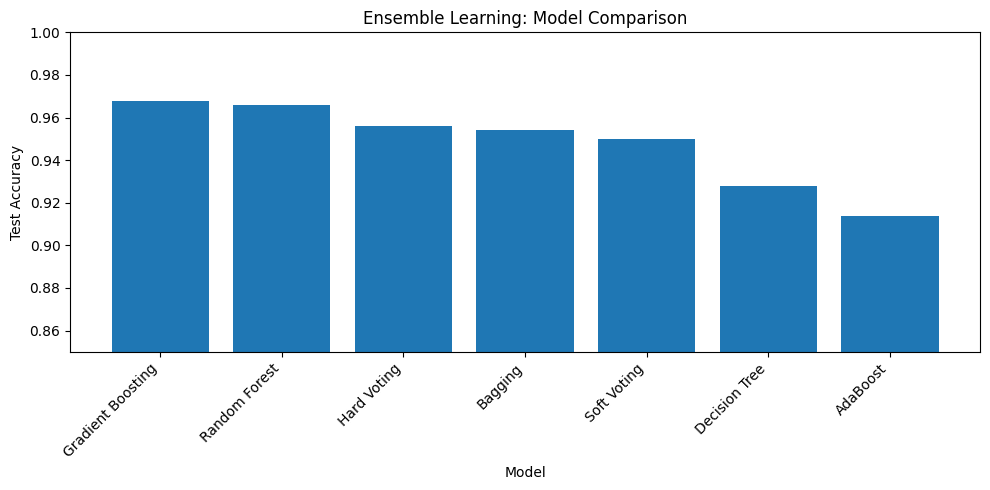

In [21]:
# Plot model accuracies
plt.figure(figsize=(10, 5))

plt.bar(results["Model"], results["Test Accuracy"])

plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.title("Ensemble Learning: Model Comparison")
plt.ylim(0.85, 1.0)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()